# Power Demand and Weather Analysis

This notebook adapts the reference electricity-consumption analysis to the supplied five-minute power-demand dataset, and is set up so its results can be **compared directly with the smart-meter notebook** (Section 8).

**Dataset:** January 1, 2021 through December 12, 2024, with weather observations and a precomputed `moving_avg_3` column. The supplied file contains 393,440 records; quality and coverage figures are recalculated below.

**Analysis:** data quality, descriptive statistics, weather relationships, calendar patterns, forecasting (two horizons), unsupervised anomaly screening, and a side-by-side comparison with the smart-meter models.

**Units:** the CSV does not document the unit for `Power demand`, so values are reported as recorded and are not labeled kW or MW.

**Comparison settings** (same as the smart-meter notebook): chronological 80/20 split, `random_state=42`, and the same model line-up (mean baseline, persistence, Linear Regression, Ridge, Random Forest, Gradient Boosting).

Install packages if needed: `pip install numpy pandas matplotlib seaborn scikit-learn`.

In [17]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingRegressor, IsolationForest, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# The notebook looks for the CSV in these places, in order. Edit the list if your file is elsewhere.
CANDIDATES = [
    Path(r"C:\Users\ITS Laptop\Desktop\Acad\AIDS\Mini_project\powerdemand_5min_2021_to_2024_with_weather.csv"),
    Path("powerdemand_5min_2021_to_2024_with_weather.csv"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:  # last resort: any matching CSV beside the notebook
    matches = sorted(Path(".").glob("powerdemand_5min*weather*.csv"))
    DATA_PATH = matches[0] if matches else None
if DATA_PATH is None:
    raise FileNotFoundError("Could not find the power-demand CSV. Put it beside this notebook or edit CANDIDATES.")

df = pd.read_csv(DATA_PATH, parse_dates=["datetime"])
index_columns = [c for c in df.columns if c.lower().startswith("unnamed:")]
df = df.drop(columns=index_columns)
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")
df = (df.dropna(subset=["datetime"]).sort_values("datetime")
        .drop_duplicates(subset="datetime").reset_index(drop=True))

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Loaded: C:\Users\ITS Laptop\Desktop\Acad\AIDS\Mini_project\powerdemand_5min_2021_to_2024_with_weather.csv
Shape: (393440, 14)


,datetime,Power demand,temp,dwpt,rhum,wdir,wspd,pres,year,month,day,hour,minute,moving_avg_3
0,2021-01-01 00:30:00,2014.00,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,30,NaN
1,2021-01-01 00:35:00,2005.63,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,35,NaN
2,2021-01-01 00:40:00,1977.60,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,40,1999.076667
3,2021-01-01 00:45:00,1976.44,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,45,1986.556667
4,2021-01-01 00:50:00,1954.37,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,50,1969.470000


## 1. Data quality and preprocessing

The file has a small amount of missing weather data and a precomputed moving average. Missing model inputs are imputed inside each model. The source moving average is excluded from forecasting because its exact calculation is undocumented and may include the current target.

In [18]:
print("Time range:", df["datetime"].min(), "to", df["datetime"].max())
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_rows").assign(
    missing_percent=lambda x: (100 * x["missing_rows"] / len(df)).round(3)
))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate timestamps:", int(df["datetime"].duplicated().sum()))

cadence = pd.Timedelta(minutes=5)
time_deltas = df["datetime"].diff()
print("\nMost common time steps:")
display(time_deltas.value_counts().head(10).rename_axis("time_step").to_frame("count"))
print("Gaps longer than five minutes:", int((time_deltas > cadence).sum()))
implied_missing = ((time_deltas[time_deltas > cadence] // cadence) - 1).sum()
print("Missing five-minute slots implied by gaps:", int(implied_missing))

expected = int((df["datetime"].max() - df["datetime"].min()) / cadence) + 1
print(f"Observed / expected slots: {len(df):,} / {expected:,}")
print(f"Observed coverage: {100 * len(df) / expected:.2f}%")

Time range: 2021-01-01 00:30:00 to 2024-12-12 00:30:00
Missing values by column:


,missing_rows,missing_percent
datetime,0,0.000
Power demand,0,0.000
temp,0,0.000
dwpt,0,0.000
rhum,0,0.000
wdir,540,0.137
wspd,0,0.000
pres,0,0.000
year,0,0.000
month,0,0.000


Duplicate rows: 0
Duplicate timestamps: 0

Most common time steps:


,count
time_step,
0 days 00:05:00,392289
0 days 00:10:00,272
0 days 00:15:00,267
0 days 00:20:00,93
0 days 01:20:00,52
0 days 01:25:00,46
0 days 00:25:00,42
0 days 01:05:00,37
0 days 01:10:00,33


Gaps longer than five minutes: 1150
Missing five-minute slots implied by gaps: 21569
Observed / expected slots: 393,440 / 415,009
Observed coverage: 94.80%


In [19]:
# Derive calendar features from datetime, not duplicated CSV fields.
df["hour"] = df["datetime"].dt.hour
df["day_of_week"] = df["datetime"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# Wind direction is circular, so use sine/cosine encodings in models.
df["wdir_sin"] = np.sin(np.deg2rad(df["wdir"]))
df["wdir_cos"] = np.cos(np.deg2rad(df["wdir"]))

demand_col = "Power demand"
weather_cols = ["temp", "dwpt", "rhum", "wspd", "pres", "wdir_sin", "wdir_cos"]
summary_cols = [demand_col, "temp", "dwpt", "rhum", "wdir", "wspd", "pres"]
display(df[summary_cols].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Power demand,393440.0,3960.736,1300.474,1302.08,3074.9,3832.32,4870.465,8631.53
temp,393440.0,25.528,7.982,4.00,20.0,27.00,31.000,46.40
dwpt,393440.0,16.338,7.377,-8.60,10.4,15.40,23.900,30.30
rhum,393440.0,63.436,24.851,5.00,44.0,67.00,84.000,100.00
wdir,392900.0,163.777,116.888,0.00,50.0,160.00,270.000,360.00
wspd,393440.0,7.855,5.664,0.00,5.4,7.60,11.200,63.00
pres,393440.0,1008.933,6.903,989.60,1003.0,1009.00,1015.000,1027.00


## 2. Descriptive statistics and distributions

Demand values are shown in their recorded units. Weather variables are summarized separately so their scales do not obscure the demand distribution.

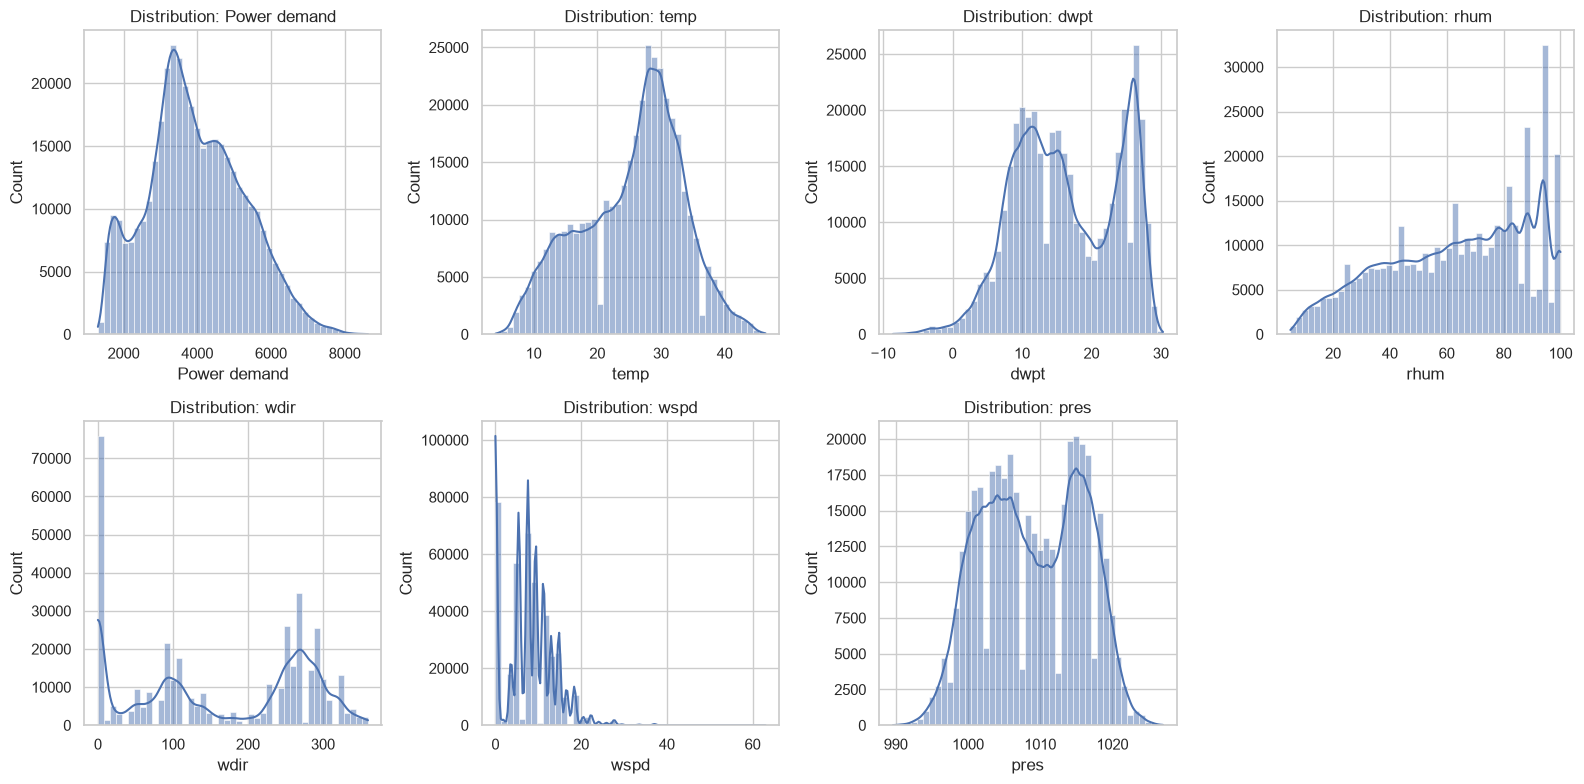

,count,mean,std,min,1%,25%,50%,75%,99%,max
Power demand,393440.0,3960.74,1300.47,1302.08,1544.98,3074.9,3832.32,4870.46,7048.83,8631.53
temp,393440.0,25.53,7.98,4.00,8.00,20.0,27.00,31.00,42.00,46.40
dwpt,393440.0,16.34,7.38,-8.60,0.40,10.4,15.40,23.90,28.10,30.30
rhum,393440.0,63.44,24.85,5.00,10.00,44.0,67.00,84.00,100.00,100.00
wdir,392900.0,163.78,116.89,0.00,0.00,50.0,160.00,270.00,350.00,360.00
wspd,393440.0,7.85,5.66,0.00,0.00,5.4,7.60,11.20,24.10,63.00
pres,393440.0,1008.93,6.90,989.60,995.50,1003.0,1009.00,1015.00,1022.00,1027.00


In [20]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), summary_cols):
    sns.histplot(df[col].dropna(), bins=45, kde=True, ax=ax)
    ax.set_title(f"Distribution: {col}")
    ax.set_xlabel(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

display(df[summary_cols].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T.round(2))

## 3. Correlation analysis

Pearson correlation highlights linear relationships; Spearman correlation captures monotonic relationships. Correlation is descriptive and does not establish causation. Raw wind direction is omitted because compass angles wrap at 360 degrees.

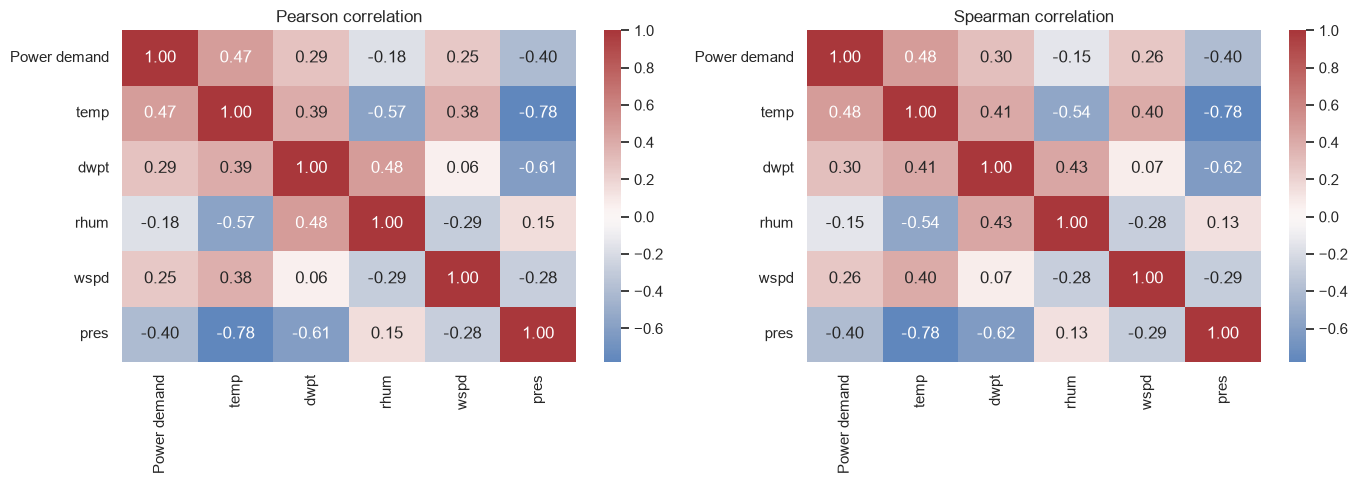

Weather-variable correlation with demand (Pearson):


,correlation
temp,0.470
pres,-0.404
dwpt,0.285
wspd,0.253
rhum,-0.177


In [21]:
corr_cols = [demand_col, "temp", "dwpt", "rhum", "wspd", "pres"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df[corr_cols].corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
    ax.set_title(f"{method.title()} correlation")
plt.tight_layout()
plt.show()

print("Weather-variable correlation with demand (Pearson):")
display(df[corr_cols].corr()["Power demand"].drop("Power demand")
        .sort_values(key=lambda x: x.abs(), ascending=False)
        .to_frame("correlation").round(3))

## 4. Daily, weekly, and monthly demand patterns

Aggregated views make the multi-year five-minute series easier to read and reveal recurring calendar patterns.

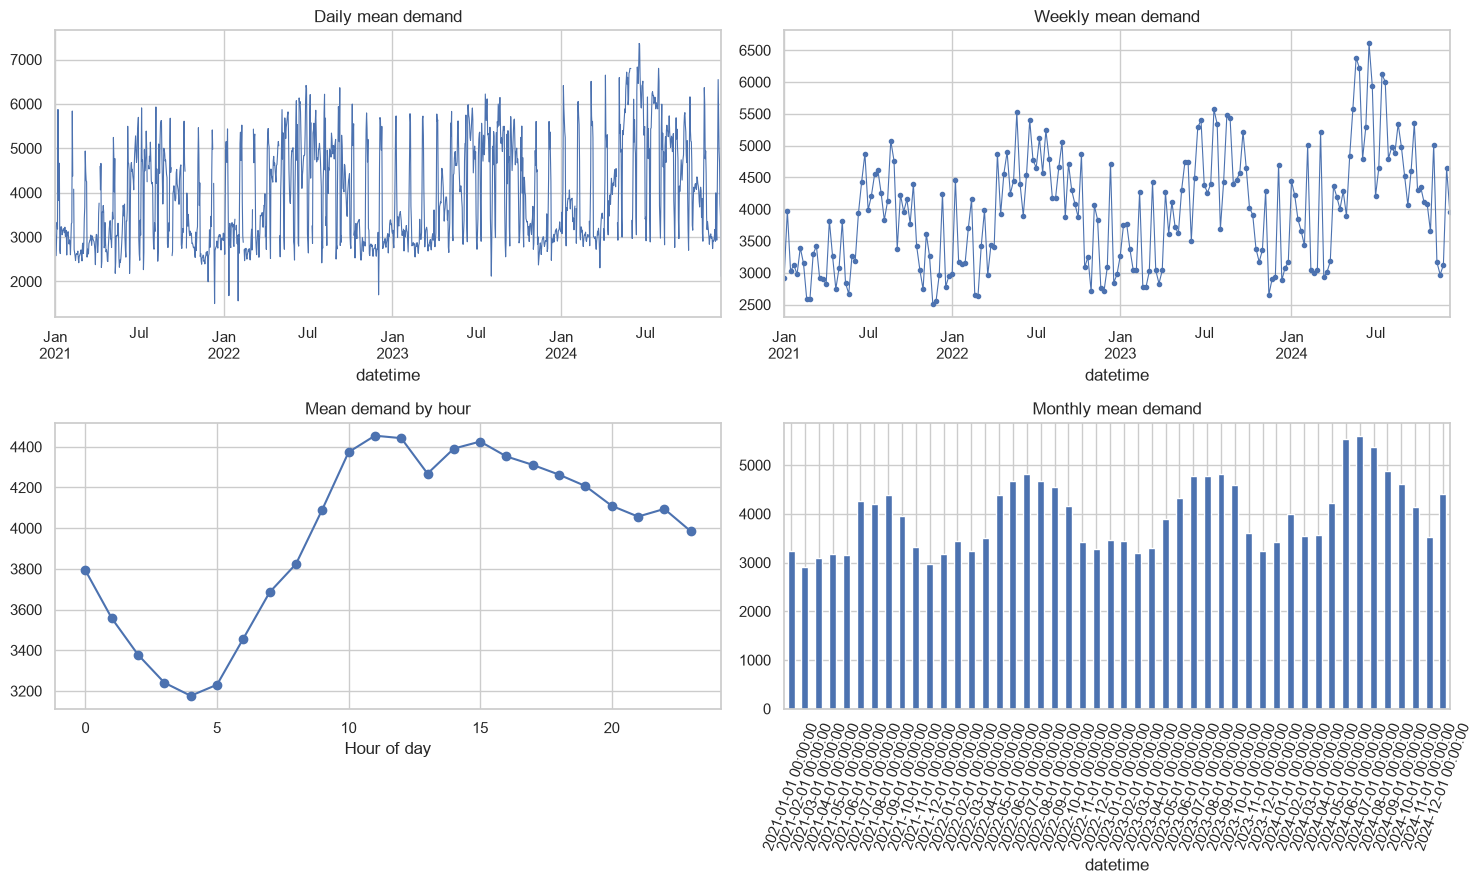

,mean_demand
Mon,3939.87
Tue,4029.47
Wed,4083.00
Thu,3966.41
Fri,3986.58
Sat,3906.26
Sun,3815.38


In [22]:
time_df = df.set_index("datetime").sort_index()
daily_mean = time_df[demand_col].resample("D").mean()
weekly_mean = time_df[demand_col].resample("W").mean()
monthly_mean = time_df[demand_col].resample("MS").mean()

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
daily_mean.plot(ax=axes[0, 0], linewidth=0.8)
axes[0, 0].set_title("Daily mean demand")
weekly_mean.plot(ax=axes[0, 1], marker=".", linewidth=0.8)
axes[0, 1].set_title("Weekly mean demand")
df.groupby("hour")[demand_col].mean().plot(ax=axes[1, 0], marker="o")
axes[1, 0].set_title("Mean demand by hour")
axes[1, 0].set_xlabel("Hour of day")
monthly_mean.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Monthly mean demand")
axes[1, 1].tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_mean = df.groupby("day_of_week")[demand_col].mean()
weekday_mean.index = weekday_names
display(weekday_mean.to_frame("mean_demand").round(2))

## 5. Forecasting demand ahead (two horizons, same models as the smart-meter notebook)

The target is demand a fixed number of steps ahead of the **forecast origin**:

- **next 5 min** (1 step), the original task of this notebook, and
- **next 30 min** (6 steps), which matches the 30-minute reading interval of the smart-meter dataset, so the two projects can be compared fairly.

Features use only information available at the origin: current demand, exact-time lags, a trailing one-hour mean, current weather, and cyclical calendar features. Reindexing to a complete five-minute grid preserves lag timing across gaps. The split is chronological (first 80% train, last 20% test). The source `moving_avg_3` is not used because it may include the current target.

**Target:** with `PREDICT_CHANGE = True` (default) the models learn the *change* from current demand (`future demand - current demand`) and the current demand is added back, so all reported errors are still errors in demand. Tree models cannot predict values outside the range they saw in training, and demand keeps rising into 2024 (the test period peaks higher than any training value), so predicting the level makes Random Forest and Gradient Boosting look much worse than they are. Linear models give identical predictions either way. Set `PREDICT_CHANGE = False` to reproduce the level-target results.

**Models:** a mean baseline, **persistence** (predict "no change from now"), Linear Regression, Ridge, Random Forest and Gradient Boosting (`HistGradientBoostingRegressor`, a fast scikit-learn implementation).

**Metrics:** MAE, RMSE and R², plus three scale-free columns used for comparison across datasets: `NRMSE (RMSE/std)`, `Skill vs persistence (%)` and `Skill vs mean (%)`. Skill is `100 * (1 - RMSE / RMSE_of_the_reference)`; positive means better than the reference, negative means worse.

In [23]:
# ---- Settings shared with the smart-meter notebook ----
RANDOM_STATE = 42                  # same seed
TRAIN_FRACTION = 0.8               # same chronological 80/20 split
MAX_TREE_ROWS = 100_000            # cap Random Forest training rows for runtime
PREDICT_CHANGE = True              # True: models learn (future demand - current demand); False: learn the demand level
HORIZONS = {"next 5 min": 1, "next 30 min": 6}   # label -> number of 5-minute steps ahead

base = df.set_index("datetime").sort_index()
full_index = pd.date_range(base.index.min(), base.index.max(), freq="5min", name="datetime")
grid = base.reindex(full_index)

# Exact five-minute-grid lags: 5 min, 15 min, 1 hour, and 24 hours.
for lag in [1, 3, 12, 288]:
    grid[f"lag_{lag}"] = grid[demand_col].shift(lag)
grid["rolling_mean_1h"] = grid[demand_col].shift(1).rolling(12, min_periods=6).mean()

hour_fraction = grid.index.hour + grid.index.minute / 60
dow = grid.index.dayofweek
month = grid.index.month
grid["hour_sin"] = np.sin(2 * np.pi * hour_fraction / 24)
grid["hour_cos"] = np.cos(2 * np.pi * hour_fraction / 24)
grid["dow_sin"] = np.sin(2 * np.pi * dow / 7)
grid["dow_cos"] = np.cos(2 * np.pi * dow / 7)
grid["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
grid["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)

feature_cols = ([demand_col, "lag_1", "lag_3", "lag_12", "lag_288", "rolling_mean_1h"]
                + weather_cols
                + ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "month_sin", "month_cos"])
print("Feature count:", len(feature_cols))
print("Missing feature values on the grid (imputed inside each model):")
display(grid[feature_cols].isna().sum().to_frame("missing_rows").query("missing_rows > 0"))

Feature count: 19
Missing feature values on the grid (imputed inside each model):


,missing_rows
Power demand,21569
lag_1,21570
lag_3,21572
lag_12,21576
lag_288,21842
rolling_mean_1h,19682
temp,21569
dwpt,21569
rhum,21569
wspd,21569


In [24]:
def make_models():
    return {
        "Linear Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)),
        "Random Forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(n_estimators=100, max_depth=24, min_samples_leaf=5,
                                  random_state=RANDOM_STATE, n_jobs=-1)),
        # HistGradientBoostingRegressor handles missing values natively.
        "Gradient Boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1,
                                                           random_state=RANDOM_STATE),
    }

def regression_metrics(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R2": r2_score(actual, predicted)}

def add_scale_free_metrics(results, y_true_std):
    """Columns that stay comparable across datasets with different units and scales."""
    results = results.copy()
    results["NRMSE (RMSE/std)"] = results["RMSE"] / y_true_std
    if "Persistence (current demand)" in results.index:
        ref = results.loc["Persistence (current demand)", "RMSE"]
        results["Skill vs persistence (%)"] = 100 * (1 - results["RMSE"] / ref)
    if "Mean baseline" in results.index:
        ref = results.loc["Mean baseline", "RMSE"]
        results["Skill vs mean (%)"] = 100 * (1 - results["RMSE"] / ref)
    return results

def run_forecast(steps):
    data = (grid.assign(target=grid[demand_col].shift(-steps))
                .dropna(subset=[demand_col, "target"]))
    X, y = data[feature_cols], data["target"]
    split_at = int(len(data) * TRAIN_FRACTION)
    X_train, X_test = X.iloc[:split_at], X.iloc[split_at:]
    y_train, y_test = y.iloc[:split_at], y.iloc[split_at:]
    tree_pos = np.linspace(0, len(X_train) - 1, min(MAX_TREE_ROWS, len(X_train)), dtype=int)

    # Optionally learn the change from current demand instead of the level, then add the current demand back.
    cur_train, cur_test = X_train[demand_col], X_test[demand_col]
    y_fit = (y_train - cur_train) if PREDICT_CHANGE else y_train
    offset = cur_test.to_numpy() if PREDICT_CHANGE else 0.0

    models = make_models()
    preds = {"Mean baseline": np.full(len(y_test), y_train.mean()),
             "Persistence (current demand)": X_test[demand_col].to_numpy()}
    for name, model in models.items():
        if name == "Random Forest":
            model.fit(X_train.iloc[tree_pos], y_fit.iloc[tree_pos])   # capped for runtime
        else:
            model.fit(X_train, y_fit)
        preds[name] = model.predict(X_test) + offset

    results = pd.DataFrame({n: regression_metrics(y_test, p) for n, p in preds.items()}).T
    results = add_scale_free_metrics(results, float(y_test.std()))
    return {"results": results, "models": models, "preds": preds, "y_test": y_test,
            "X_test": X_test, "train_period": (data.index[0], data.index[split_at - 1]),
            "test_period": (data.index[split_at], data.index[-1]),
            "n_train": len(X_train), "n_test": len(X_test), "tree_rows": len(tree_pos)}

runs = {label: run_forecast(steps) for label, steps in HORIZONS.items()}

for label, run in runs.items():
    print(f"\n=== Forecast horizon: {label} ===")
    print("Train:", run["train_period"][0], "to", run["train_period"][1], f"({run['n_train']:,} rows)")
    print("Test: ", run["test_period"][0], "to", run["test_period"][1], f"({run['n_test']:,} rows)")
    print("Random Forest training rows:", f"{run['tree_rows']:,}")
    display(run["results"].sort_values("RMSE").round(3))


=== Forecast horizon: next 5 min ===
Train: 2021-01-01 00:30:00 to 2024-02-28 13:00:00 (313,831 rows)
Test:  2024-02-28 13:05:00 to 2024-12-12 00:25:00 (78,458 rows)
Random Forest training rows: 100,000


,MAE,RMSE,R2,NRMSE (RMSE/std),Skill vs persistence (%),Skill vs mean (%)
Gradient Boosting,23.115,40.659,0.999,0.029,9.334,97.444
Ridge,25.836,43.199,0.999,0.031,3.671,97.285
Linear Regression,25.835,43.199,0.999,0.031,3.671,97.285
Persistence (current demand),28.611,44.845,0.999,0.033,0.000,97.181
Random Forest,25.090,50.147,0.999,0.036,-11.824,96.848
Mean baseline,1269.614,1590.999,-0.331,1.154,-3447.788,0.000



=== Forecast horizon: next 30 min ===
Train: 2021-01-01 00:30:00 to 2024-02-27 14:05:00 (311,489 rows)
Test:  2024-02-27 14:10:00 to 2024-12-12 00:00:00 (77,873 rows)
Random Forest training rows: 100,000


,MAE,RMSE,R2,NRMSE (RMSE/std),Skill vs persistence (%),Skill vs mean (%)
Random Forest,53.987,126.177,0.992,0.092,26.076,92.054
Gradient Boosting,61.930,143.394,0.989,0.104,15.989,90.970
Ridge,89.196,155.819,0.987,0.113,8.709,90.187
Linear Regression,89.195,155.821,0.987,0.113,8.709,90.187
Persistence (current demand),114.030,170.685,0.985,0.124,0.000,89.251
Mean baseline,1266.035,1587.919,-0.334,1.155,-830.322,0.000


In [25]:
for label, run in runs.items():
    models_only = run["results"].drop(index=["Mean baseline", "Persistence (current demand)"])
    best = models_only["RMSE"].idxmin()
    persist_rmse = run["results"].loc["Persistence (current demand)", "RMSE"]
    print(f"{label}: best model = {best} (RMSE {models_only.loc[best, 'RMSE']:.3f} vs persistence {persist_rmse:.3f}, "
          f"skill vs persistence {models_only.loc[best, 'Skill vs persistence (%)']:.1f}%)")

next 5 min: best model = Gradient Boosting (RMSE 40.659 vs persistence 44.845, skill vs persistence 9.3%)
next 30 min: best model = Random Forest (RMSE 126.177 vs persistence 170.685, skill vs persistence 26.1%)


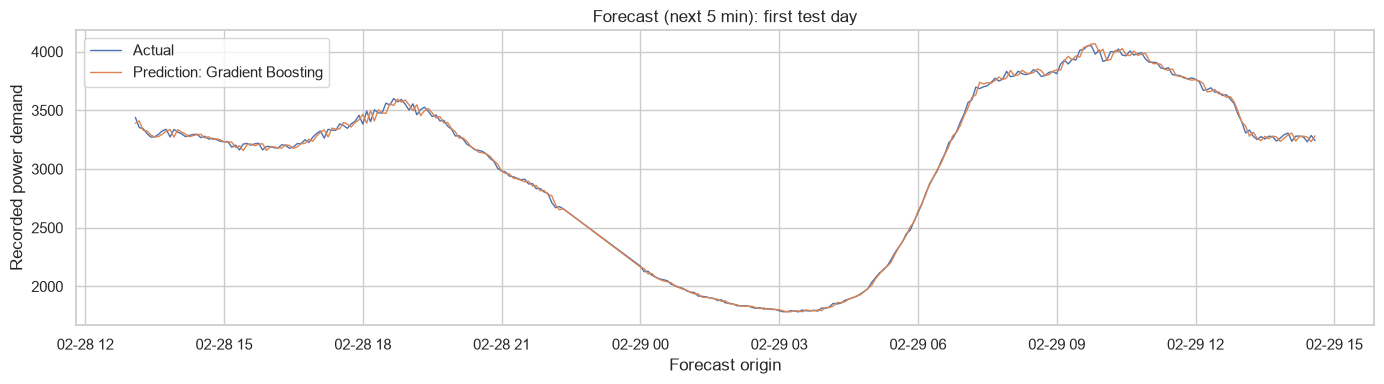

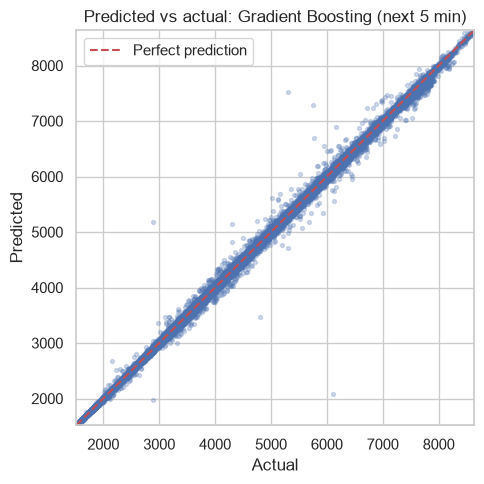

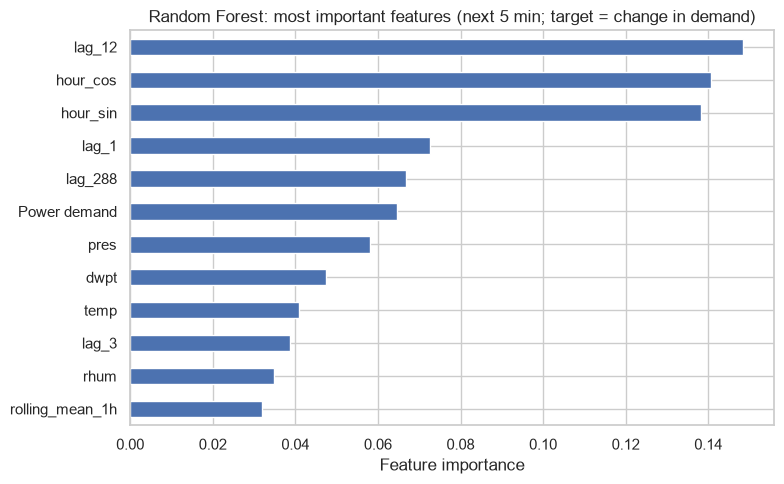

In [26]:
primary = next(iter(runs))                      # first horizon (next 5 min)
target_desc = "change in demand" if PREDICT_CHANGE else "demand level"
run = runs[primary]
y_test, preds = run["y_test"], run["preds"]
best_name = run["results"].drop(index=["Mean baseline", "Persistence (current demand)"])["RMSE"].idxmin()
best_prediction = preds[best_name]
n = min(288, len(y_test))  # first test day

plt.figure(figsize=(14, 4))
plt.plot(y_test.index[:n], y_test.iloc[:n].values, label="Actual", linewidth=1)
plt.plot(y_test.index[:n], best_prediction[:n], label=f"Prediction: {best_name}", linewidth=1)
plt.title(f"Forecast ({primary}): first test day")
plt.xlabel("Forecast origin"); plt.ylabel("Recorded power demand")
plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(5, 5))
plt.scatter(y_test, best_prediction, s=8, alpha=0.25)
limits = [min(float(y_test.min()), float(np.min(best_prediction))),
          max(float(y_test.max()), float(np.max(best_prediction)))]
plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.xlim(limits); plt.ylim(limits)
plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.title(f"Predicted vs actual: {best_name} ({primary})")
plt.legend(); plt.tight_layout(); plt.show()

rf = run["models"]["Random Forest"].named_steps["randomforestregressor"]
pd.Series(rf.feature_importances_, index=feature_cols).sort_values().tail(12).plot(
    kind="barh", figsize=(8, 5), title=f"Random Forest: most important features ({primary}; target = {target_desc})")
plt.xlabel("Feature importance"); plt.tight_layout(); plt.show()

## 6. Unsupervised anomaly screening

This dataset has no ground-truth anomaly labels. Isolation Forest therefore produces **candidate readings for review**, not confirmed faults. The 1% contamination setting is a screening threshold and should be adjusted to the use case.

In [27]:
anomaly_X = df.copy()
anomaly_X["hour_sin"] = np.sin(2 * np.pi * (df["hour"] + df["datetime"].dt.minute / 60) / 24)
anomaly_X["hour_cos"] = np.cos(2 * np.pi * (df["hour"] + df["datetime"].dt.minute / 60) / 24)
anomaly_X["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
anomaly_X["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)
anomaly_cols = [demand_col, "temp", "dwpt", "rhum", "wspd", "pres",
                "wdir_sin", "wdir_cos", "hour_sin", "hour_cos", "dow_sin", "dow_cos"]
Xa = anomaly_X[anomaly_cols]

fit_rows = min(100_000, len(Xa))
fit_positions = np.linspace(0, len(Xa) - 1, fit_rows, dtype=int)
anomaly_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    IsolationForest(n_estimators=150, contamination=0.01,
                    random_state=42, n_jobs=-1)
)
anomaly_model.fit(Xa.iloc[fit_positions])
df["anomaly_candidate"] = anomaly_model.predict(Xa) == -1

print("Candidate readings:", int(df["anomaly_candidate"].sum()))
print(f"Candidate share: {100 * df['anomaly_candidate'].mean():.2f}%")
display(df.loc[df["anomaly_candidate"],
               ["datetime", demand_col, "temp", "dwpt", "rhum", "wdir", "wspd", "pres"]].head(10))

Candidate readings: 3923
Candidate share: 1.00%


,datetime,Power demand,temp,dwpt,rhum,wdir,wspd,pres
19821,2021-03-12 19:40:00,3060.34,25.0,11.9,44.0,180.0,27.7,1016.0
19826,2021-03-12 20:05:00,2945.15,25.0,11.9,44.0,180.0,27.7,1016.0
19827,2021-03-12 20:10:00,2932.61,25.0,11.9,44.0,180.0,27.7,1016.0
19828,2021-03-12 20:15:00,2893.78,25.0,11.9,44.0,180.0,27.7,1016.0
19829,2021-03-12 20:20:00,2874.99,25.0,11.9,44.0,180.0,27.7,1016.0
19830,2021-03-12 20:25:00,2843.82,25.0,11.9,44.0,180.0,27.7,1016.0
19831,2021-03-12 20:30:00,2833.49,23.0,10.8,46.0,160.0,29.5,1014.8
19832,2021-03-12 20:35:00,2783.21,23.0,10.8,46.0,160.0,29.5,1014.8
19833,2021-03-12 20:40:00,2770.23,23.0,10.8,46.0,160.0,29.5,1014.8
19834,2021-03-12 20:45:00,2750.19,23.0,10.8,46.0,160.0,29.5,1014.8


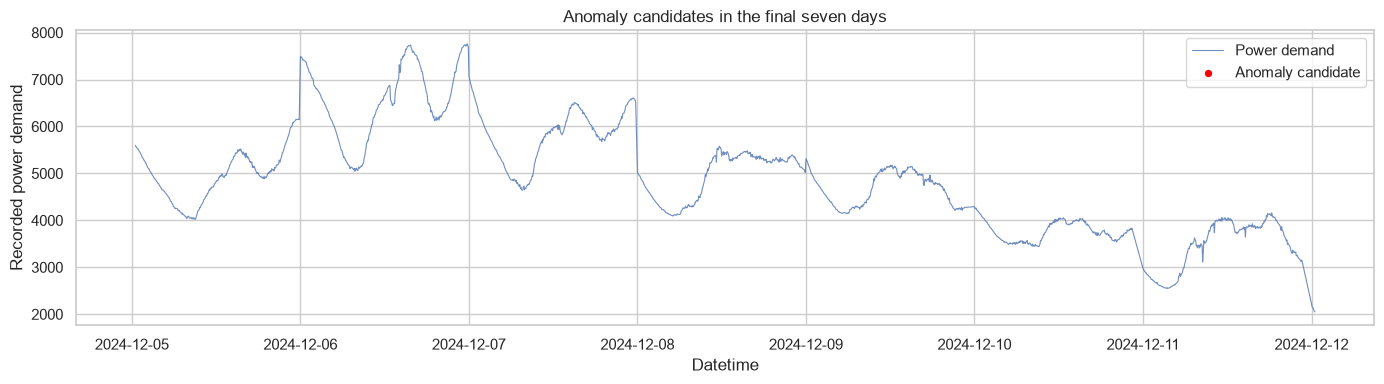

In [28]:
window_start = df["datetime"].max() - pd.Timedelta(days=7)
recent = df[df["datetime"] >= window_start]
candidates = recent[recent["anomaly_candidate"]]

plt.figure(figsize=(14, 4))
plt.plot(recent["datetime"], recent[demand_col], linewidth=0.8, alpha=0.8, label="Power demand")
plt.scatter(candidates["datetime"], candidates[demand_col],
            s=18, color="red", label="Anomaly candidate", zorder=3)
plt.title("Anomaly candidates in the final seven days")
plt.xlabel("Datetime"); plt.ylabel("Recorded power demand")
plt.legend(); plt.tight_layout(); plt.show()

## 7. Comparison with the smart-meter notebook

The two projects use different units and scales (the smart-meter data are min-max scaled to 0-1; this dataset is in raw recorded units), so **raw MAE and RMSE cannot be compared**. Instead the table uses scale-free measures:

- **R²**: share of variance explained (1 = perfect, 0 = no better than the mean).
- **NRMSE**: RMSE divided by the standard deviation of the test targets (lower is better; equals `sqrt(1 - R²)` for an unbiased model).
- **Skill vs persistence (%)**: improvement over "no change from now". This is the most honest score for time series: a series with strong autocorrelation gives R² close to 1 even for the naive guess.

The smart-meter numbers below were taken from that notebook's chronological 80/20 test set (991 readings, 30-minute interval, rounded to 3 decimals). Persistence there is the previous 30-minute reading (`Lag_1`) on the same split. To use your own latest run instead, save its results table with `results.to_csv("results_smart_meter.csv")` in the same folder as this notebook; the cell below will pick it up automatically.

Smart meter (30 min)                                           Power demand (5 min)                   \
                                               R2 NRMSE (RMSE/std) Skill vs persistence (%)                   R2 NRMSE (RMSE/std)   
Mean baseline                              -0.004            1.001                   29.831               -0.331            1.154   
Persistence (current demand)               -1.038            1.427                    0.000                0.999            0.033   
Linear Regression                           0.236            0.876                   38.608                0.999            0.031   
Ridge                                       0.232            0.876                   38.608                0.999            0.031   
Random Forest                               0.195            0.895                   37.311                0.999            0.036   
Gradient Boosting                           0.217            0.882                   38.176                0.999            0.029   

                                                      Power demand (30 min)                                            
                             Skill vs persistence (%)                    R2 NRMSE (RMSE/std) Skill vs persistence (%)  
Mean baseline                               -3447.788                -0.334            1.155                 -830.322  
Persistence (current demand)                    0.000                 0.985            0.124                    0.000  
Linear Regression                               3.671                 0.987            0.113                    8.709  
Ridge                                           3.671                 0.987            0.113                    8.709  
Random Forest                                 -11.824                 0.992            0.092                   26.076  
Gradient Boosting                               9.334                 0.989            0.104                   15.989

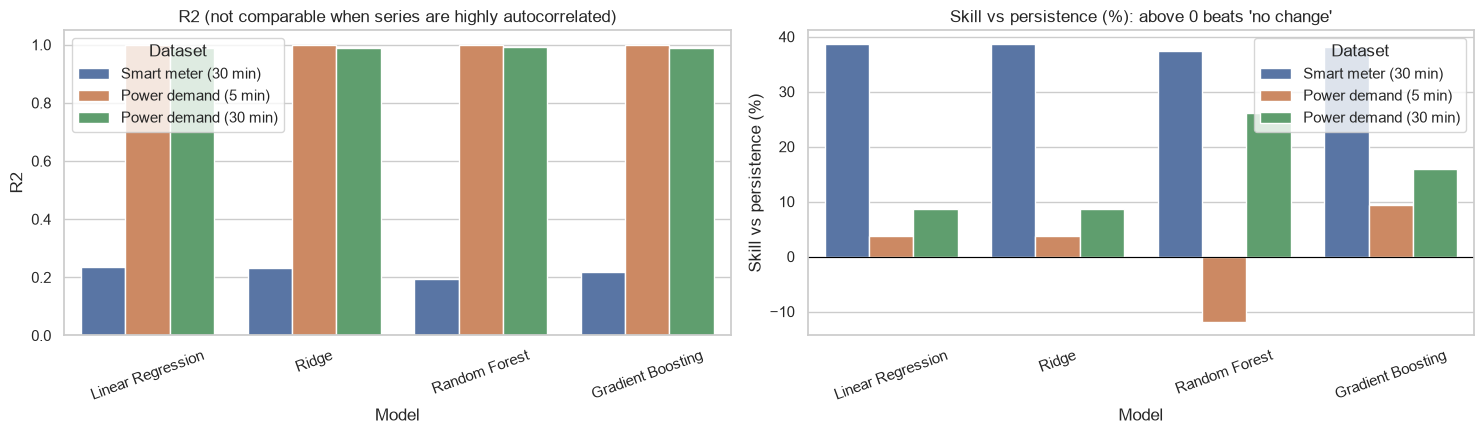

Saved results_power_demand.csv


In [29]:
# ---- Smart-meter results (30-min readings, scaled 0-1) ----
smart_meter = pd.DataFrame(
    {"MAE":  [0.1304, 0.1875, 0.113, 0.114, 0.117, 0.116],
     "RMSE": [0.1623, 0.2313, 0.142, 0.142, 0.145, 0.143],
     "R2":   [-0.004, -1.038, 0.236, 0.232, 0.195, 0.217]},
    index=["Mean baseline", "Persistence (current demand)", "Linear Regression",
           "Ridge", "Random Forest", "Gradient Boosting"])
smart_std = 0.1621                 # standard deviation of the smart-meter test targets

custom = Path("results_smart_meter.csv")
if custom.exists():
    loaded = pd.read_csv(custom, index_col=0)
    loaded.index = loaded.index.str.replace("Mean baseline.*", "Mean baseline", regex=True)
    smart_meter = loaded[["MAE", "RMSE", "R2"]]
    print("Using", custom)
smart_meter = add_scale_free_metrics(smart_meter, smart_std)

series = {"Smart meter (30 min)": smart_meter}
for label, run in runs.items():
    series[f"Power demand ({label.replace('next ', '')})"] = run["results"]

model_order = ["Mean baseline", "Persistence (current demand)", "Linear Regression", "Ridge",
               "Random Forest", "Gradient Boosting"]
cols = ["R2", "NRMSE (RMSE/std)", "Skill vs persistence (%)"]
comparison = pd.concat({k: v.reindex(model_order)[cols] for k, v in series.items()}, axis=1)
display(comparison.round(3))

# Bar charts: R2 and skill vs persistence for the four real models
real_models = ["Linear Regression", "Ridge", "Random Forest", "Gradient Boosting"]
long = []
for k, v in series.items():
    for m in real_models:
        if m in v.index:
            long.append({"Dataset": k, "Model": m, "R2": v.loc[m, "R2"],
                         "Skill vs persistence (%)": v.loc[m].get("Skill vs persistence (%)", np.nan)})
long = pd.DataFrame(long)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=long, x="Model", y="R2", hue="Dataset", ax=axes[0])
axes[0].set_title("R2 (not comparable when series are highly autocorrelated)")
sns.barplot(data=long, x="Model", y="Skill vs persistence (%)", hue="Dataset", ax=axes[1])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Skill vs persistence (%): above 0 beats 'no change'")
for ax in axes: ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

# Save this notebook's results in the same shape, so the comparison can be rerun elsewhere
pd.concat({k: v for k, v in series.items() if k.startswith("Power")}, names=["Dataset", "Model"]) \
  .to_csv("results_power_demand.csv")
print("Saved results_power_demand.csv")

### How to read the comparison

- **Persistence tells the two datasets apart.** In the smart-meter data the previous reading is a poor guess, because consecutive values are almost independent. In the power-demand data it is a very strong guess, because demand changes smoothly.
- **R² alone is misleading here.** For power demand even the naive persistence guess scores an R² close to 1, so R² cannot separate the models. Use *Skill vs persistence* and *NRMSE*.
- **The horizon matters.** A 5-minute forecast is much easier than a 30-minute one; use the 30-minute rows when comparing with the smart-meter results.
- **Weather and calendar** are informative in this real dataset (see Sections 3 and 4) but were not in the smart-meter data, which is why the smart-meter models stayed close to the mean baseline.
- **Tree models and the target.** With `PREDICT_CHANGE = False` Random Forest and Gradient Boosting score far below persistence here, because the test period goes above the training range. Learning the change removes that artefact. The smart-meter models predicted the level, which was fine there because that series has no trend.
- **Caveats:** different datasets, size, resolution and (for smart meter) extra input `Avg_Past_Consumption`; this is a comparison of how well the same modelling recipe works on each dataset, not a ranking of the datasets.

## 8. Automatic summary of the results

In [30]:
print("DATA")
print(f"  Records: {len(df):,} | period: {df['datetime'].min():%Y-%m-%d} to {df['datetime'].max():%Y-%m-%d}")
print(f"  Observed / expected five-minute slots: {len(df):,} / {expected:,} ({100 * len(df) / expected:.1f}% coverage)")
print(f"  Strongest weather correlation with demand: "
      f"{df[corr_cols].corr()[demand_col].drop(demand_col).abs().idxmax()} "
      f"(r = {df[corr_cols].corr()[demand_col].drop(demand_col)[df[corr_cols].corr()[demand_col].drop(demand_col).abs().idxmax()]:.2f})")
print("\nFORECASTING")
for label, run in runs.items():
    r = run["results"]
    models_only = r.drop(index=["Mean baseline", "Persistence (current demand)"])
    best = models_only["RMSE"].idxmin()
    print(f"  {label}: best = {best}; RMSE {models_only.loc[best, 'RMSE']:.2f} vs persistence "
          f"{r.loc['Persistence (current demand)', 'RMSE']:.2f} "
          f"(skill {models_only.loc[best, 'Skill vs persistence (%)']:.1f}%, R2 {models_only.loc[best, 'R2']:.4f})")
print("\nANOMALIES")
print(f"  Isolation Forest candidates: {int(df['anomaly_candidate'].sum()):,} "
      f"({100 * df['anomaly_candidate'].mean():.2f}% of readings); unlabeled, so these need review")

DATA
  Records: 393,440 | period: 2021-01-01 to 2024-12-12
  Observed / expected five-minute slots: 393,440 / 415,009 (94.8% coverage)
  Strongest weather correlation with demand: temp (r = 0.47)

FORECASTING
  next 5 min: best = Gradient Boosting; RMSE 40.66 vs persistence 44.84 (skill 9.3%, R2 0.9991)
  next 30 min: best = Random Forest; RMSE 126.18 vs persistence 170.68 (skill 26.1%, R2 0.9916)

ANOMALIES
  Isolation Forest candidates: 3,923 (1.00% of readings); unlabeled, so these need review


## 9. Conclusions

Use the tables above and the automatic summary to write the conclusions. Points that apply to this notebook:

- **Data quality:** the series is not perfectly continuous (see the coverage and gap figures), so lags are computed on a complete five-minute grid and rows without a known target are dropped.
- **Demand and weather:** temperature has the strongest correlation with demand, but correlation is not causation and pressure and temperature are themselves related.
- **Forecasting:** a model adds value only if its *Skill vs persistence* is clearly above 0 on the chronological test set. Compare the 30-minute rows with the smart-meter notebook.
- **Anomaly candidates:** Isolation Forest flags unusual readings without labels; inspect the flagged timestamps in context before calling them faults.

**Limitations:** the dataset does not state the power-demand unit; observations are not perfectly continuous; the source moving average is excluded because its calculation is undocumented; the forecasts assume current weather is available at the forecast origin; and the smart-meter comparison uses a different dataset, interval and feature set.